# Porto Seguro Safe Driver Prediction – 03 Modelling and Model Selection

**Goal:** compare the classifiers of the course on the same cross-validation folds, tune the most promising
ones, and select the final model, which is then evaluated once on the held-out test part in notebook 04.

All results are 5-fold stratified cross-validation scores on the **training part only** (protocol of
notebook 02, section 6). Main metric: normalised Gini; also reported: PR-AUC and the train Gini (overfitting).

**Workflow**
1. Setup: imports, shared project code, results of notebook 02
2. Load data and split (identical to notebooks 01–02)
3. `calc` ablation: are the 20 `calc` features useful?
4. Logistic regression: tuning the regularization strength
5. Other classifiers: decision tree, Naive Bayes, neural network (MLP)
6. Ensembles I – random forest: tuning with the out-of-bag estimate
7. Ensembles II – gradient boosting: randomized hyperparameter search
8. Class imbalance: class weights vs no weights
9. Feature engineering: number of missing values per row
10. Ensembles III – soft voting of the best models
11. Comparison of all models and choice of the final model
12. Summary and next steps

**Run time:** about 80 minutes on a laptop with 8 cores and 16 GB RAM (mostly sections 6, 7 and 10).

## 1. Setup

In [1]:
# 1. Imports, shared project code and settings
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import loguniform, randint, uniform
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeClassifier

# shared project code lives in ../src (same loading, split, preparation and evaluation for every notebook)
sys.path.insert(0, str(Path.cwd().parent))
from src.data_utils import RANDOM_STATE, load_data, split_features_target, train_test_parts
from src.preprocessing import (make_linear_preprocessor, make_tree_preprocessor, categorical_columns,
                               add_missing_count)
from src.evaluation import CV_FOLDS, SCORING, evaluate, search_summary, best_params, gini_from_auc

RESULTS_DIR = Path('../results')
plt.rcParams['figure.dpi'] = 90

# every model result of this notebook is collected here (one dictionary per model)
results = []

In [2]:
# 1. Results of notebook 02 (dummy baseline and default models), the starting point of the comparison
first_results = pd.read_csv(RESULTS_DIR / '02_first_models_cv.csv', index_col='model')
print(first_results.round(4).to_string())

                                   gini_mean  gini_std  pr_auc_mean  pr_auc_std  train_gini  fit_time_s
model                                                                                                  
Dummy (constant claim rate)           0.0000    0.0000       0.0364      0.0000      0.0000      0.9516
Logistic regression (default)         0.2573    0.0063       0.0637      0.0012      0.2721     16.9057
Hist. gradient boosting (default)     0.2525    0.0100       0.0618      0.0013      0.4071     33.7638


## 2. Load data and split

In [3]:
# 2. Load data (-1 recoded as NaN) and the stratified 80/20 split, shared with notebooks 01 and 02
data = load_data()
features, target = split_features_target(data)
X_train, X_test, y_train, y_test = train_test_parts(features, target)
del data, features  # free memory: only the training part is used in this notebook

all_columns = list(X_train.columns)
print(f"training part: {len(y_train):,} rows, claim rate {y_train.mean():.4%}")

training part: 476,169 rows, claim rate 3.6447%


## 3. `calc` ablation
The EDA (notebook 01, section 8) found that every `calc` feature is as weak as random noise. Here the two
default models of notebook 02 are cross-validated again without the 20 `calc` features: if the Gini does not
drop, the features are removed (simpler and faster models, less overfitting).

In [4]:
# 3. Default logistic regression and gradient boosting, with and without the calc features
def default_logistic_regression(drop_calc):
    return Pipeline([('prepare', make_linear_preprocessor(all_columns, drop_calc=drop_calc)),
                     ('model', LogisticRegression(max_iter=1000))])

def default_gradient_boosting(drop_calc):
    return Pipeline([('prepare', make_tree_preprocessor(all_columns, drop_calc=drop_calc)),
                     ('model', HistGradientBoostingClassifier(
                         categorical_features=categorical_columns(all_columns, drop_calc=drop_calc),
                         random_state=RANDOM_STATE))])

ablation = []
for drop_calc in (False, True):
    label = 'without calc' if drop_calc else 'with calc'
    ablation.append(evaluate(default_logistic_regression(drop_calc), X_train, y_train,
                             f'Logistic regression (default), {label}'))
    ablation.append(evaluate(default_gradient_boosting(drop_calc), X_train, y_train,
                             f'Hist. gradient boosting (default), {label}'))

ablation_df = pd.DataFrame(ablation).set_index('model').sort_index()
print(ablation_df[['gini_mean', 'gini_std', 'pr_auc_mean', 'train_gini', 'fit_time_s']].round(4).to_string())

                                                 gini_mean  gini_std  pr_auc_mean  train_gini  fit_time_s
model                                                                                                    
Hist. gradient boosting (default), with calc        0.2525    0.0100       0.0618      0.4071     26.1532
Hist. gradient boosting (default), without calc     0.2522    0.0065       0.0622      0.4106     19.3696
Logistic regression (default), with calc            0.2573    0.0063       0.0637      0.2721     21.1224
Logistic regression (default), without calc         0.2582    0.0056       0.0638      0.2714     13.4421


**Observations:**
- Removing the 20 `calc` features changes the CV Gini by +0.0009 (logistic regression) and -0.0003 (gradient
  boosting). Both differences are about ten times smaller than the standard deviation over the folds.
- The models train faster without them (logistic regression 21 s → 13 s per fold, gradient boosting 26 s → 19 s),
  and the fold-to-fold spread of gradient boosting gets smaller (0.0100 → 0.0065).
- This confirms the EDA: the `calc` features carry no signal. They are dropped, which leaves 37 features.

In [5]:
# 3. Decision from the ablation: the calc features are removed in all following models
DROP_CALC = True
model_columns = [col for col in all_columns if '_calc_' not in col]
print(f"{len(model_columns)} features used from here on")

37 features used from here on


## 4. Logistic regression: regularization strength
The only important hyperparameter is `C`, the inverse of the L2 penalty: a small `C` means strong
regularization (smaller weights, simpler model). Grid search on the same 5 folds.

In [6]:
# 4. Grid search over C (logistic regression without calc features)
logistic_pipeline = Pipeline([('prepare', make_linear_preprocessor(all_columns, drop_calc=DROP_CALC)),
                              ('model', LogisticRegression(max_iter=2000))])
logistic_search = GridSearchCV(logistic_pipeline, {'model__C': [0.001, 0.01, 0.1, 1, 10]},
                               scoring=SCORING, refit=False, cv=CV_FOLDS, n_jobs=-1, return_train_score=True)
logistic_search.fit(X_train, y_train)

logistic_curve = pd.DataFrame({
    'C': logistic_search.cv_results_['param_model__C'].astype(float),
    'cv_gini': gini_from_auc(logistic_search.cv_results_['mean_test_roc_auc']),
    'cv_gini_std': 2 * logistic_search.cv_results_['std_test_roc_auc'],
    'train_gini': gini_from_auc(logistic_search.cv_results_['mean_train_roc_auc']),
})
print(logistic_curve.round(4).to_string(index=False))
best_logistic_params = best_params(logistic_search)
print("best:", best_logistic_params)
results.append(search_summary(logistic_search, 'Logistic regression (tuned C)'))

     C  cv_gini  cv_gini_std  train_gini
 0.001   0.2561       0.0038      0.2613
 0.010   0.2592       0.0049      0.2688
 0.100   0.2587       0.0058      0.2713
 1.000   0.2582       0.0056      0.2714
10.000   0.2582       0.0058      0.2715
best: {'model__C': 0.01}


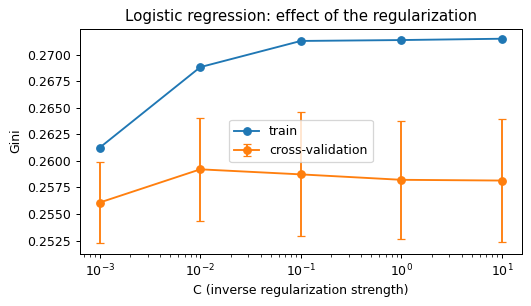

In [7]:
# 4. Train and CV Gini as a function of C
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(logistic_curve['C'], logistic_curve['train_gini'], marker='o', label='train')
ax.errorbar(logistic_curve['C'], logistic_curve['cv_gini'], yerr=logistic_curve['cv_gini_std'],
            marker='o', capsize=3, label='cross-validation')
ax.set_xscale('log')
ax.set_xlabel('C (inverse regularization strength)')
ax.set_ylabel('Gini')
ax.set_title('Logistic regression: effect of the regularization')
ax.legend()
plt.tight_layout()
plt.show()

**Observations:**
- `C = 0.01` gives the best CV Gini (0.2592), but it is only 0.001 above `C ≥ 1`. That is far less than the
  standard deviation over the folds (about 0.005), so the regularization strength hardly matters.
- The train Gini is only about 0.01 above the CV Gini for every `C`, so the logistic regression does **not**
  overfit. Its limit is bias: a linear model cannot represent interactions or non-monotonic effects (e.g. the
  U-shape of `ps_car_14` from the EDA).
- `C = 0.001` is too strong: train and CV Gini both drop, which is underfitting.

## 5. Other classifiers
**Decision tree:** a single tree overfits easily (notebook 01 of the course: error vs depth), so its depth and
minimum leaf size are tuned with a grid search.

In [8]:
# 5. Decision tree: grid over the maximum depth and the minimum number of rows per leaf
tree_pipeline = Pipeline([('prepare', make_tree_preprocessor(all_columns, drop_calc=DROP_CALC)),
                          ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))])
tree_search = GridSearchCV(tree_pipeline,
                           {'model__max_depth': [4, 6, 8, 10, 12, 15],
                            'model__min_samples_leaf': [50, 200, 1000]},
                           scoring=SCORING, refit=False, cv=CV_FOLDS, n_jobs=-1, return_train_score=True)
tree_search.fit(X_train, y_train)

tree_grid = pd.DataFrame({
    'max_depth': tree_search.cv_results_['param_model__max_depth'].astype(int),
    'min_samples_leaf': tree_search.cv_results_['param_model__min_samples_leaf'].astype(int),
    'cv_gini': gini_from_auc(tree_search.cv_results_['mean_test_roc_auc']),
    'train_gini': gini_from_auc(tree_search.cv_results_['mean_train_roc_auc']),
})
print("CV Gini (rows: max_depth, columns: min_samples_leaf)")
print(tree_grid.pivot(index='max_depth', columns='min_samples_leaf', values='cv_gini').round(4))
print("best:", best_params(tree_search))
results.append(search_summary(tree_search, 'Decision tree (tuned)'))

CV Gini (rows: max_depth, columns: min_samples_leaf)
min_samples_leaf    50      200     1000
max_depth                               
4                 0.1903  0.1903  0.1905
6                 0.2100  0.2117  0.2114
8                 0.2099  0.2108  0.2172
10                0.1879  0.1964  0.2174
12                0.1561  0.1861  0.2139
15                0.1179  0.1677  0.2091
best: {'model__max_depth': 10, 'model__min_samples_leaf': 1000}


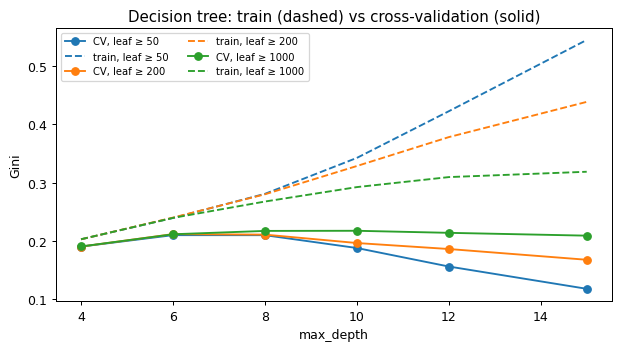

In [9]:
# 5. Train vs CV Gini as a function of the depth (for each leaf size): overfitting made visible
fig, ax = plt.subplots(figsize=(7, 4))
for leaf_size, group in tree_grid.groupby('min_samples_leaf'):
    line = ax.plot(group['max_depth'], group['cv_gini'], marker='o', label=f'CV, leaf ≥ {leaf_size}')
    ax.plot(group['max_depth'], group['train_gini'], linestyle='--', color=line[0].get_color(),
            label=f'train, leaf ≥ {leaf_size}')
ax.set_xlabel('max_depth')
ax.set_ylabel('Gini')
ax.set_title('Decision tree: train (dashed) vs cross-validation (solid)')
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Naive Bayes and neural network.** Gaussian Naive Bayes is the simplest probabilistic model; it assumes
independent, normally distributed features (it needs the dense linear preparation; only 2 folds run in parallel
to limit the memory). The multi-layer perceptron uses the linear preparation, mini-batches and early stopping
on 10% of the training folds; two sizes are compared.

kNN and SVM, also covered in the course, are **not** used: kNN must compare every new driver with ~380,000
training rows (slow prediction, and distances are not meaningful on 200 mostly one-hot dimensions), and a
kernel SVM needs time between quadratic and cubic in the number of rows, which is impractical at this size.

In [10]:
# 5. Gaussian Naive Bayes (dense input) and two MLP sizes
naive_bayes = Pipeline([('prepare', make_linear_preprocessor(all_columns, drop_calc=DROP_CALC, sparse=False)),
                        ('model', GaussianNB())])
results.append(evaluate(naive_bayes, X_train, y_train, 'Gaussian Naive Bayes', n_jobs=2))

for hidden_layers in [(32,), (64, 32)]:
    mlp = Pipeline([('prepare', make_linear_preprocessor(all_columns, drop_calc=DROP_CALC)),
                    ('model', MLPClassifier(hidden_layer_sizes=hidden_layers, alpha=1e-3, batch_size=1024,
                                            early_stopping=True, n_iter_no_change=5,
                                            random_state=RANDOM_STATE))])
    results.append(evaluate(mlp, X_train, y_train, f'MLP {hidden_layers}'))

print(pd.DataFrame(results[-3:]).set_index('model').round(4).to_string())

                      gini_mean  gini_std  pr_auc_mean  pr_auc_std  train_gini  fit_time_s
model                                                                                     
Gaussian Naive Bayes     0.1792    0.0067       0.0493      0.0007      0.1955      5.8809
MLP (32,)                0.2573    0.0153       0.0624      0.0024      0.2828     20.9715
MLP (64, 32)             0.2492    0.0028       0.0606      0.0013      0.2635     31.3624


**Observations:**
- **Decision tree:** the plot shows overfitting very clearly. With leaves of at least 50 rows, the train Gini
  rises from 0.20 (depth 4) to 0.54 (depth 15) while the CV Gini falls from 0.21 (depth 6) to 0.12. A large minimum leaf
  size (1000 rows) acts as regularization and keeps the CV Gini flat. The best tree (depth 10, leaf ≥ 1000)
  reaches 0.217, still clearly below the logistic regression: a single tree gives only a few distinct scores
  (one per leaf), so its ranking of the drivers is coarse.
- **Gaussian Naive Bayes** is the weakest model (0.179). Its assumptions do not hold here: the one-hot columns of
  one feature depend on each other, and binary features are not normally distributed. It is also the fastest
  model (6 s per fold).
- **MLP:** the small network (32 units) matches the default logistic regression (0.257). Its fold-to-fold spread
  is more than twice as large (0.015 vs 0.006), because early stopping on a small validation split is noisy. The larger network
  (64, 32) is worse (0.249). Extra capacity does not help, so the data has little non-linear signal that a small
  neural network can use.

## 6. Ensembles I – random forest
A random forest averages many deep trees, each grown on a bootstrap sample and with a random subset of
features at every split. Each tree is grown on 30% of the rows (`max_samples=0.3`), which speeds up training
and makes the trees more diverse.

**Tuning with the out-of-bag (OOB) estimate:** every row is left out of about 70% of the trees; scoring each
row only with those trees gives a validation estimate from a single fit, without cross-validation. This
makes the tuning about 5 times cheaper. The best configuration is then cross-validated like all other models.

In [11]:
# 6. OOB Gini for a small grid of leaf sizes and feature subsets (one fit per configuration)
X_train_tree = make_tree_preprocessor(all_columns, drop_calc=DROP_CALC).fit_transform(X_train)  # column selection only

oob_rows = []
for max_features in ['sqrt', 0.4]:
    for min_samples_leaf in [30, 100, 300]:
        start = time.time()
        forest = RandomForestClassifier(n_estimators=200, max_samples=0.3, max_features=max_features,
                                        min_samples_leaf=min_samples_leaf, oob_score=True,
                                        n_jobs=-1, random_state=RANDOM_STATE)
        forest.fit(X_train_tree, y_train)
        oob_rows.append({'max_features': max_features, 'min_samples_leaf': min_samples_leaf,
                         'oob_gini': gini_from_auc(roc_auc_score(y_train, forest.oob_decision_function_[:, 1])),
                         'fit_time_s': time.time() - start})
del forest

oob_df = pd.DataFrame(oob_rows)
print(oob_df.round(4).to_string(index=False))
best_forest_row = oob_df.loc[oob_df['oob_gini'].idxmax()]
best_forest_params = {'max_features': best_forest_row['max_features'],
                      'min_samples_leaf': int(best_forest_row['min_samples_leaf'])}
print("best:", best_forest_params)

max_features  min_samples_leaf  oob_gini  fit_time_s
        sqrt                30    0.2654     89.2796
        sqrt               100    0.2716     82.1084
        sqrt               300    0.2664     80.3665
         0.4                30    0.2625    149.8389
         0.4               100    0.2696    116.7019
         0.4               300    0.2684    102.5605
best: {'max_features': 'sqrt', 'min_samples_leaf': 100}


In [12]:
# 6. Cross-validation of the best configuration with 300 trees (folds run one after the other,
#    because the forest itself already uses all cores)
def make_random_forest(params):
    return Pipeline([('prepare', make_tree_preprocessor(all_columns, drop_calc=DROP_CALC)),
                     ('model', RandomForestClassifier(n_estimators=300, max_samples=0.3, n_jobs=-1,
                                                      random_state=RANDOM_STATE, **params))])

results.append(evaluate(make_random_forest(best_forest_params), X_train, y_train,
                        'Random forest (tuned)', n_jobs=1))
print(pd.DataFrame(results[-1:]).set_index('model').round(4).to_string())

                       gini_mean  gini_std  pr_auc_mean  pr_auc_std  train_gini  fit_time_s
model                                                                                      
Random forest (tuned)     0.2704    0.0079       0.0641       0.002      0.4602     55.4379


**Observations:**
- The OOB Gini peaks at a minimum leaf size of 100 rows. Smaller leaves (30) overfit and larger leaves (300)
  are too coarse. `sqrt` (6 of 37 features per split) beats 40% of the features and trains about twice as fast:
  fewer features per split make the trees more diverse, and averaging diverse trees reduces the variance more.
- The 5-fold CV Gini of the chosen forest (0.2704 ± 0.0079) is very close to its OOB estimate (0.2716). The OOB
  tuning was therefore reliable, at about a fifth of the cost of cross-validation.
- The random forest is the best single model so far, 0.011 above the tuned logistic regression. Its train Gini
  (0.46) is much higher than the CV Gini. For a forest this is expected (each tree fits its own sample) and does
  not mean poor generalization, because the averaging cancels most of the individual trees' errors.

## 7. Ensembles II – gradient boosting
Gradient boosting adds small trees one after the other, each correcting the errors of the previous ones. With
default settings it overfitted strongly (notebook 02: train Gini 0.41 vs CV 0.25). A randomized search over
20 configurations tunes the learning rate, the tree size, the leaf size, the L2 penalty and the share of
features per split. The number of trees is not searched: early stopping ends the training when the Gini on an
internal 10% validation split of the training folds has not improved for 50 rounds.

In [13]:
# 7. Randomized search for histogram gradient boosting (without calc features)
boosting_pipeline = Pipeline([
    ('prepare', make_tree_preprocessor(all_columns, drop_calc=DROP_CALC)),
    ('model', HistGradientBoostingClassifier(
        max_iter=1000, early_stopping=True, scoring='roc_auc', validation_fraction=0.1,
        n_iter_no_change=50, categorical_features=categorical_columns(all_columns, drop_calc=DROP_CALC),
        random_state=RANDOM_STATE)),
])
boosting_space = {
    'model__learning_rate': loguniform(0.02, 0.1),
    'model__max_leaf_nodes': randint(7, 48),
    'model__min_samples_leaf': randint(50, 1000),
    'model__l2_regularization': loguniform(0.1, 30),
    'model__max_features': uniform(0.3, 0.7),
}
boosting_search = RandomizedSearchCV(boosting_pipeline, boosting_space, n_iter=20, scoring=SCORING,
                                     refit=False, cv=CV_FOLDS, n_jobs=-1, return_train_score=True,
                                     random_state=RANDOM_STATE)
boosting_search.fit(X_train, y_train)

search_table = pd.DataFrame(boosting_search.cv_results_['params'])
search_table.columns = [name.replace('model__', '') for name in search_table.columns]
search_table['cv_gini'] = gini_from_auc(boosting_search.cv_results_['mean_test_roc_auc'])
search_table['train_gini'] = gini_from_auc(boosting_search.cv_results_['mean_train_roc_auc'])
print("Five best configurations:")
print(search_table.sort_values('cv_gini', ascending=False).head(5).round(4).to_string(index=False))

best_boosting_params = best_params(boosting_search)
results.append(search_summary(boosting_search, 'Hist. gradient boosting (tuned)'))

Five best configurations:
 l2_regularization  learning_rate  max_features  max_leaf_nodes  min_samples_leaf  cv_gini  train_gini
            3.1986         0.0263        0.3455              10               650   0.2660      0.3588
            0.2688         0.0375        0.4276              10                51   0.2638      0.3681
           24.6597         0.0735        0.5132               8               389   0.2629      0.3699
            0.4965         0.0479        0.3986              21               862   0.2624      0.4280
           12.7541         0.0412        0.3668              29               623   0.2611      0.4402


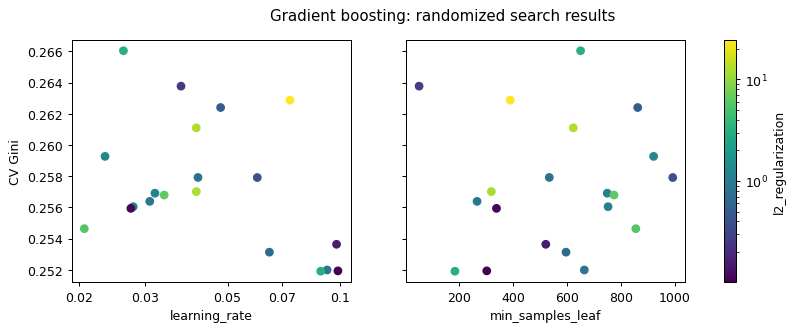

In [14]:
# 7. CV Gini of all configurations against the learning rate and the leaf size
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, param in zip(axes, ['learning_rate', 'min_samples_leaf']):
    points = ax.scatter(search_table[param], search_table['cv_gini'], c=search_table['l2_regularization'],
                        cmap='viridis', norm=LogNorm())
    ax.set_xlabel(param)
axes[0].set_xscale('log')
# plain tick labels (0.02, 0.03, ...) instead of overlapping powers of ten
axes[0].set_xticks([0.02, 0.03, 0.05, 0.07, 0.1], labels=['0.02', '0.03', '0.05', '0.07', '0.1'])
axes[0].minorticks_off()
axes[0].set_ylabel('CV Gini')
fig.colorbar(points, ax=axes, label='l2_regularization')
fig.suptitle('Gradient boosting: randomized search results')
plt.show()

**Observations:**
- The best configuration uses a slow learning rate (0.026), small trees (10 leaves), large leaves (at least 650
  rows), a moderate L2 penalty (3.2) and 35% of the features per split. It reaches a CV Gini of 0.2660, 0.0135
  above the default model, and its train Gini drops from 0.41 to 0.36. The tuning mainly removed overfitting.
- In the scatter plot, the fastest learning rates (around 0.1) give the lowest scores. The three best
  configurations all use small trees (8–10 leaves). Simple, strongly regularized trees work best on this
  noisy target.
- The 20 configurations span only 0.252–0.266, so the model is not very sensitive to its hyperparameters.
  Even tuned, gradient boosting stays below the random forest (0.2704).

## 8. Class imbalance: class weights
With `class_weight='balanced'`, every claim counts about 26 times as much as a non-claim in the loss, so that
both classes have the same total weight. This changes the predicted probabilities (they are no longer
calibrated), but the Gini only depends on the ranking: the question is whether the weighting leads to a
better ranking. Tested on the tuned logistic regression and gradient boosting.

In [15]:
# 8. Tuned logistic regression and gradient boosting with balanced class weights
def make_logistic_regression(params, class_weight=None, extra_features=False):
    columns = all_columns + ['n_missing'] if extra_features else all_columns
    steps = [('add_count', FunctionTransformer(add_missing_count))] if extra_features else []
    steps += [('prepare', make_linear_preprocessor(columns, drop_calc=DROP_CALC)),
              ('model', LogisticRegression(max_iter=2000, class_weight=class_weight))]
    return Pipeline(steps).set_params(**params)

def make_gradient_boosting(params, class_weight=None, extra_features=False):
    columns = all_columns + ['n_missing'] if extra_features else all_columns
    steps = [('add_count', FunctionTransformer(add_missing_count))] if extra_features else []
    steps += [('prepare', make_tree_preprocessor(columns, drop_calc=DROP_CALC)),
              ('model', HistGradientBoostingClassifier(
                  max_iter=1000, early_stopping=True, scoring='roc_auc', validation_fraction=0.1,
                  n_iter_no_change=50, class_weight=class_weight,
                  categorical_features=categorical_columns(all_columns, drop_calc=DROP_CALC),
                  random_state=RANDOM_STATE))]
    return Pipeline(steps).set_params(**params)

imbalance = [
    evaluate(make_logistic_regression(best_logistic_params, class_weight='balanced'), X_train, y_train,
             'Logistic regression (tuned), balanced weights'),
    evaluate(make_gradient_boosting(best_boosting_params, class_weight='balanced'), X_train, y_train,
             'Hist. gradient boosting (tuned), balanced weights'),
]
results.extend(imbalance)

unweighted = pd.DataFrame(results).set_index('model').loc[['Logistic regression (tuned C)',
                                                            'Hist. gradient boosting (tuned)']]
print(pd.concat([unweighted, pd.DataFrame(imbalance).set_index('model')])
      [['gini_mean', 'gini_std', 'pr_auc_mean', 'train_gini']].round(4).to_string())

                                                   gini_mean  gini_std  pr_auc_mean  train_gini
model                                                                                          
Logistic regression (tuned C)                         0.2592    0.0049       0.0634      0.2688
Hist. gradient boosting (tuned)                       0.2660    0.0096       0.0650      0.3588
Logistic regression (tuned), balanced weights         0.2588    0.0057       0.0631      0.2731
Hist. gradient boosting (tuned), balanced weights     0.2647    0.0086       0.0644      0.3748


**Observations:**
- Balanced class weights make both models slightly worse: logistic regression 0.2592 → 0.2588, gradient boosting
  0.2660 → 0.2647. Both changes are smaller than the fold standard deviation.
- This is expected for a ranking metric. Reweighting adds no information about *which* drivers claim. For
  gradient boosting it only increases the overfitting (train Gini 0.359 → 0.375), because the few claims get a
  large weight.
- The class imbalance is therefore handled by the choice of metric (Gini and PR-AUC instead of accuracy). The
  decision threshold is chosen in notebook 04. Class weights are not used further.

## 9. Feature engineering: number of missing values per row
The EDA showed that missingness carries signal column by column (notebook 01, section 6). A new feature
`n_missing` counts the missing values of each driver; it is computed row by row, so it cannot leak information
between rows. Tested on the tuned logistic regression and gradient boosting (without class weights).

In [16]:
# 9. Tuned models with the extra feature n_missing
engineered = [
    evaluate(make_logistic_regression(best_logistic_params, extra_features=True), X_train, y_train,
             'Logistic regression (tuned) + n_missing'),
    evaluate(make_gradient_boosting(best_boosting_params, extra_features=True), X_train, y_train,
             'Hist. gradient boosting (tuned) + n_missing'),
]
results.extend(engineered)
print(pd.concat([unweighted, pd.DataFrame(engineered).set_index('model')])
      [['gini_mean', 'gini_std', 'pr_auc_mean', 'train_gini']].round(4).to_string())

                                             gini_mean  gini_std  pr_auc_mean  train_gini
model                                                                                    
Logistic regression (tuned C)                   0.2592    0.0049       0.0634      0.2688
Hist. gradient boosting (tuned)                 0.2660    0.0096       0.0650      0.3588
Logistic regression (tuned) + n_missing         0.2592    0.0049       0.0638      0.2688
Hist. gradient boosting (tuned) + n_missing     0.2667    0.0079       0.0649      0.3688


**Observations:**
- For the logistic regression `n_missing` changes nothing (0.2592). The linear model already has the
  missing-value indicators and the "missing" categories, so the count adds little new information.
- For gradient boosting the CV Gini rises by 0.0007 (0.2660 → 0.2667). That is much less than one standard
  deviation, so it is not a real improvement.
- The feature is **not** kept, so that the final model stays simpler.

## 10. Ensembles III – soft voting
The three best model families make different kinds of errors (a linear model, bagged deep trees, boosted
small trees). Soft voting averages their predicted claim probabilities; if their errors are not perfectly
correlated, the average ranks the drivers better than each model alone.

In [17]:
# 10. Soft voting of tuned logistic regression, random forest and gradient boosting
voting = VotingClassifier([
    ('logistic_regression', make_logistic_regression(best_logistic_params)),
    ('random_forest', make_random_forest(best_forest_params)),
    ('gradient_boosting', make_gradient_boosting(best_boosting_params)),
], voting='soft')
results.append(evaluate(voting, X_train, y_train, 'Soft voting (LR + RF + GB)', n_jobs=1))
print(pd.DataFrame(results[-1:]).set_index('model').round(4).to_string())

                            gini_mean  gini_std  pr_auc_mean  pr_auc_std  train_gini  fit_time_s
model                                                                                           
Soft voting (LR + RF + GB)     0.2737    0.0076       0.0657      0.0016      0.3758    136.4289


**Observations:**
- The soft voting ensemble has the best CV Gini (0.2737 ± 0.0076) and the best PR-AUC (0.0657) of all models.
  It is 0.003 above the random forest, 0.008 above gradient boosting and 0.015 above logistic regression.
- The three models make partly different errors, so their average ranks the drivers better than each model
  alone. This is the variance-reduction argument for ensembles from the course.
- Its train Gini (0.38) is lower than the forest's (0.46): averaging with the smoother logistic regression and
  boosting models makes the ensemble less specialized to the training folds.
- The price is the training time: about 2 minutes per fit, roughly the sum of the three models.

## 11. Comparison of all models and choice of the final model

In [18]:
# 11. All cross-validation results of notebooks 02 and 03, best first
comparison = pd.concat([first_results, pd.DataFrame(results).set_index('model')])
comparison = comparison.sort_values('gini_mean', ascending=False)
print(comparison[['gini_mean', 'gini_std', 'pr_auc_mean', 'train_gini', 'fit_time_s']].round(4).to_string())

comparison.to_csv(RESULTS_DIR / '03_model_comparison_cv.csv')

                                                   gini_mean  gini_std  pr_auc_mean  train_gini  fit_time_s
model                                                                                                      
Soft voting (LR + RF + GB)                            0.2737    0.0076       0.0657      0.3758    136.4289
Random forest (tuned)                                 0.2704    0.0079       0.0641      0.4602     55.4379
Hist. gradient boosting (tuned) + n_missing           0.2667    0.0079       0.0649      0.3688    160.0584
Hist. gradient boosting (tuned)                       0.2660    0.0096       0.0650      0.3588    126.5379
Hist. gradient boosting (tuned), balanced weights     0.2647    0.0086       0.0644      0.3748    127.4821
Logistic regression (tuned C)                         0.2592    0.0049       0.0634      0.2688     15.6098
Logistic regression (tuned) + n_missing               0.2592    0.0049       0.0638      0.2688     15.8011
Logistic regression (tuned),

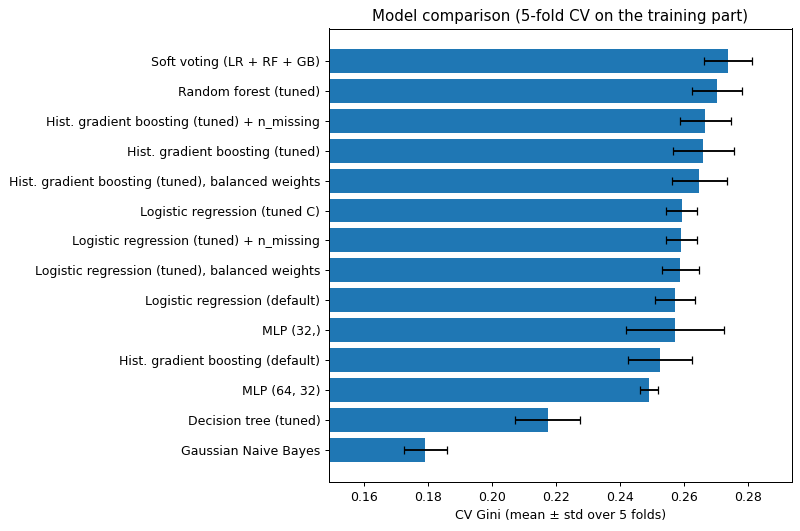

In [19]:
# 11. CV Gini of every model with one standard deviation over the folds
plot_data = comparison.drop(index='Dummy (constant claim rate)').sort_values('gini_mean')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_data.index, plot_data['gini_mean'], xerr=plot_data['gini_std'], capsize=3, color='tab:blue')
ax.set_xlabel('CV Gini (mean ± std over 5 folds)')
ax.set_xlim(plot_data['gini_mean'].min() - 0.03, plot_data['gini_mean'].max() + 0.02)
ax.set_title('Model comparison (5-fold CV on the training part)')
plt.tight_layout()
fig.savefig(RESULTS_DIR / '03_model_comparison.png', dpi=150)
plt.show()

**Choice of the final model:**
- The **soft voting ensemble of logistic regression, random forest and gradient boosting** is chosen. It has the
  highest CV Gini (0.2737) and the highest PR-AUC (0.0657), with a fold-to-fold spread similar to the single
  models.
- Its lead over the random forest (+0.003) is smaller than one standard deviation over the folds, so the two
  are close. The ensemble is still preferred: all models were scored on the same folds, it was best in both
  metrics, and averaging three different model families makes it less dependent on the weaknesses of one.
- All tuned models without `calc` features are included in the comparison, and the training time (about
  2 minutes) is acceptable. If interpretability mattered more than the last 0.015 Gini, the tuned logistic
  regression (0.259, 16 s, readable weights) would be the alternative.

**Caveat (winner's curse):** the tuned scores are slightly optimistic, because the same folds were used both to
choose the hyperparameters and to report the score. The unbiased estimate comes from the held-out test part
in notebook 04.

In [20]:
# 11. The final model (see the choice above)
FINAL_MODEL = comparison.index[0]
print("final model:", FINAL_MODEL)

final model: Soft voting (LR + RF + GB)


In [21]:
# 11. Save the chosen configuration, so that notebook 04 can refit it on the whole training part
final_configuration = {
    'final_model': FINAL_MODEL,
    'drop_calc': DROP_CALC,
    'logistic_regression': best_logistic_params,
    'random_forest': best_forest_params,
    'gradient_boosting': {name: (float(value) if isinstance(value, (float, np.floating)) else int(value))
                          for name, value in best_boosting_params.items()},
}
with open(RESULTS_DIR / '03_final_configuration.json', 'w') as file:
    json.dump(final_configuration, file, indent=2)
print(json.dumps(final_configuration, indent=2))

{
  "final_model": "Soft voting (LR + RF + GB)",
  "drop_calc": true,
  "logistic_regression": {
    "model__C": 0.01
  },
  "random_forest": {
    "max_features": "sqrt",
    "min_samples_leaf": 100
  },
  "gradient_boosting": {
    "model__l2_regularization": 3.1986171822035616,
    "model__learning_rate": 0.026316082737033224,
    "model__max_features": 0.3455361150896956,
    "model__max_leaf_nodes": 10,
    "model__min_samples_leaf": 650
  }
}


## 12. Summary and next steps

| Step | Result |
|---|---|
| `calc` ablation | no effect (±0.001), the 20 features are dropped → 37 features |
| Logistic regression | `C = 0.01`, Gini 0.259; no overfitting, limited by bias |
| Decision tree / Naive Bayes / MLP | 0.217 / 0.179 / 0.257, none beats the logistic regression |
| Random forest (OOB tuning) | Gini 0.270, best single model; OOB estimate matched the CV |
| Gradient boosting (randomized search) | Gini 0.266, overfitting reduced (train 0.41 → 0.36) |
| Class weights, `n_missing` | no improvement, not used |
| **Soft voting (LR + RF + GB)** | **Gini 0.274, PR-AUC 0.066**, chosen as the final model |

From the dummy baseline (0) and the first default models (about 0.257), the cross-validated Gini improved to
0.274. Most of the gain comes from the ensembles: bagging, boosting with regularization, and voting.
For comparison, the winning Kaggle solutions scored about 0.29 on Kaggle's own test set. They used extensive
feature engineering and large ensembles. The two numbers come from different data, so they are not directly
comparable.

**Next steps (notebook 04):** refit the final model on the whole training part, evaluate it once on the
held-out test part (Gini with a bootstrap confidence interval, ROC and precision-recall curves, lift chart,
confusion matrix at a chosen threshold), and inspect which features matter (permutation importance).